# Crop & Fertilizer Recommendation - Exploratory Data Analysis

**Datasets** (Kaggle): *Crop Recommendation Dataset* (atharvaingle) and *Fertilizer Prediction* (irakozekelly).
**Targets:** `label` (22 crops) and `Fertilizer Name` (7 fertilizers).
**Team:** Debjit Das (RA2411056010276), Anshumaan Das (RA2411056010283) - Guide: Dr. Sasikala E, DSBS, SRM Institute of Science and Technology.

Run the cells top to bottom. The notebook only reads the two CSV files in the `data/` folder of the project.

In [1]:
# Imports and project paths
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Works whether the notebook is started from notebooks/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CROP_CSV = ROOT / "data" / "Crop_recommendation.csv"
FERT_CSV = ROOT / "data" / "Fertilizer_Prediction.csv"
CROP_TARGET, FERT_TARGET = "label", "Fertilizer Name"
print("Project root:", ROOT)
print("Crop file found:", CROP_CSV.exists(), "| Fertilizer file found:", FERT_CSV.exists())

Project root: C:\Users\ROSHNI\OneDrive\Documents\GitHub\l-data-seT---ML
Crop file found: True | Fertilizer file found: True


## 1. Load datasets: shape, dtypes, head

In [2]:
crop = pd.read_csv(CROP_CSV)
fert = pd.read_csv(FERT_CSV)

for name, df in (("CROP", crop), ("FERTILIZER", fert)):
    print(f"=== {name} ===")
    print("Shape:", df.shape)
    print()
    print(df.dtypes)
    print()
crop.head()

=== CROP ===


Shape: (2200, 8)

N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

=== FERTILIZER ===
Shape: (100000, 9)

Temperature        int64
Humidity           int64
Moisture           int64
Soil Type            str
Crop Type            str
Nitrogen           int64
Potassium          int64
Phosphorous        int64
Fertilizer Name      str
dtype: object



,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
fert.head()

,Temperature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,32,51,41,Red,Ground Nuts,7,3,19,14-35-14
1,35,58,35,Black,Cotton,4,14,16,Urea
2,27,55,43,Sandy,Sugarcane,28,0,17,20-20
3,33,56,56,Loamy,Ground Nuts,37,5,24,28-28
4,32,70,60,Red,Ground Nuts,4,6,9,14-35-14


## 2. Missing value heatmap

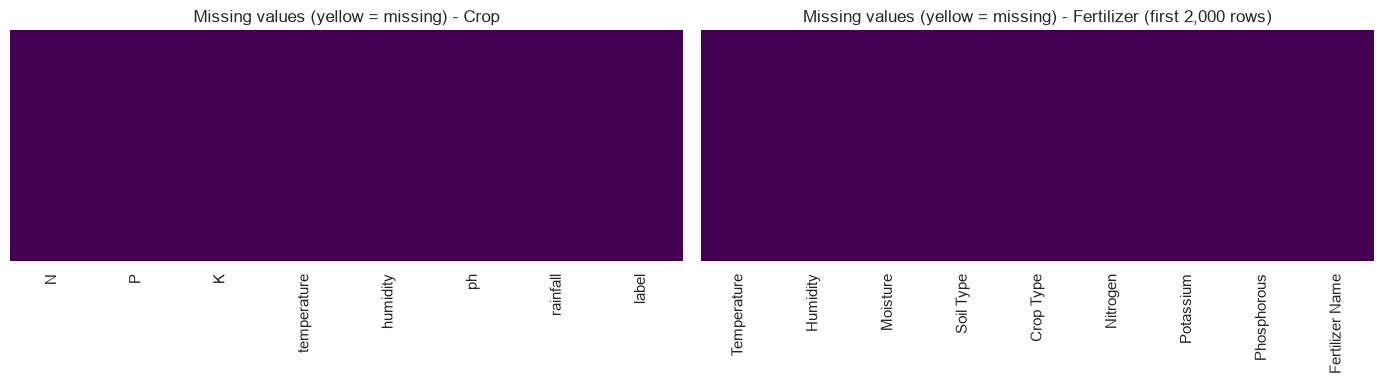

Missing values - crop: 0 | fertilizer: 0
Duplicate rows - crop: 0 | fertilizer: 0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, df) in zip(axes, (("Crop", crop), ("Fertilizer (first 2,000 rows)", fert.head(2000)))):
    sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=ax)
    ax.set_title(f"Missing values (yellow = missing) - {name}")
plt.tight_layout()
plt.show()

print("Missing values - crop:", int(crop.isnull().sum().sum()), "| fertilizer:", int(fert.isnull().sum().sum()))
print("Duplicate rows - crop:", int(crop.duplicated().sum()), "| fertilizer:", int(fert.duplicated().sum()))

## 3. Distribution of the targets

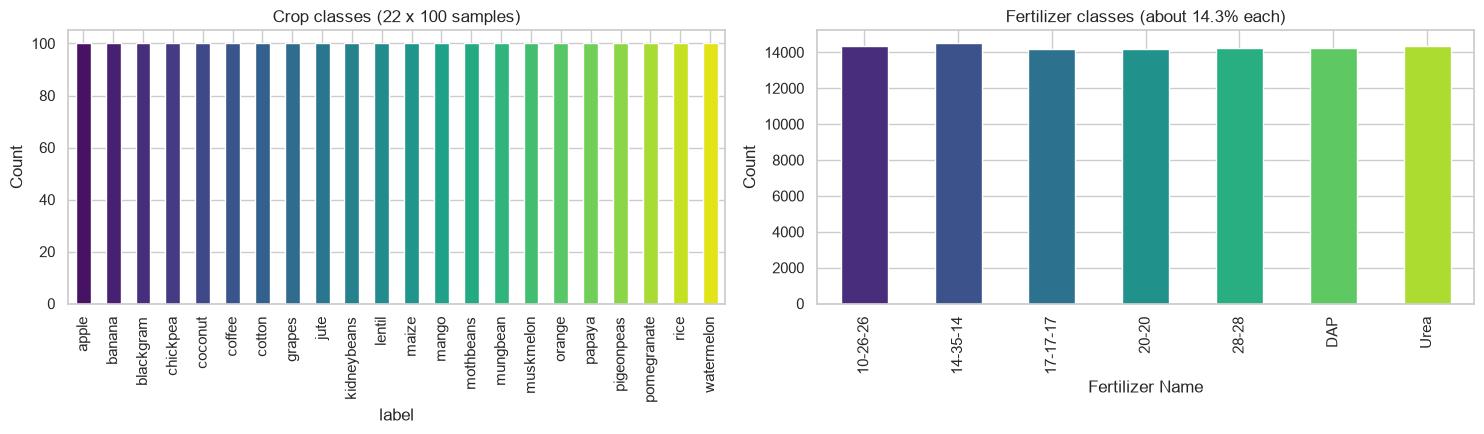

Chance-level accuracy: crop = 4.55%, fertilizer = 14.29%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
crop[CROP_TARGET].value_counts().sort_index().plot(kind="bar", color=sns.color_palette("viridis", 22), ax=axes[0])
axes[0].set_title("Crop classes (22 x 100 samples)"); axes[0].set_ylabel("Count")
fert[FERT_TARGET].value_counts().sort_index().plot(kind="bar", color=sns.color_palette("viridis", 7), ax=axes[1])
axes[1].set_title("Fertilizer classes (about 14.3% each)"); axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()
print("Chance-level accuracy: crop = %.2f%%, fertilizer = %.2f%%" % (100 / crop[CROP_TARGET].nunique(), 100 / fert[FERT_TARGET].nunique()))

## 4. Statistical summary and correlation heatmap

In [6]:
crop.describe().round(2)

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


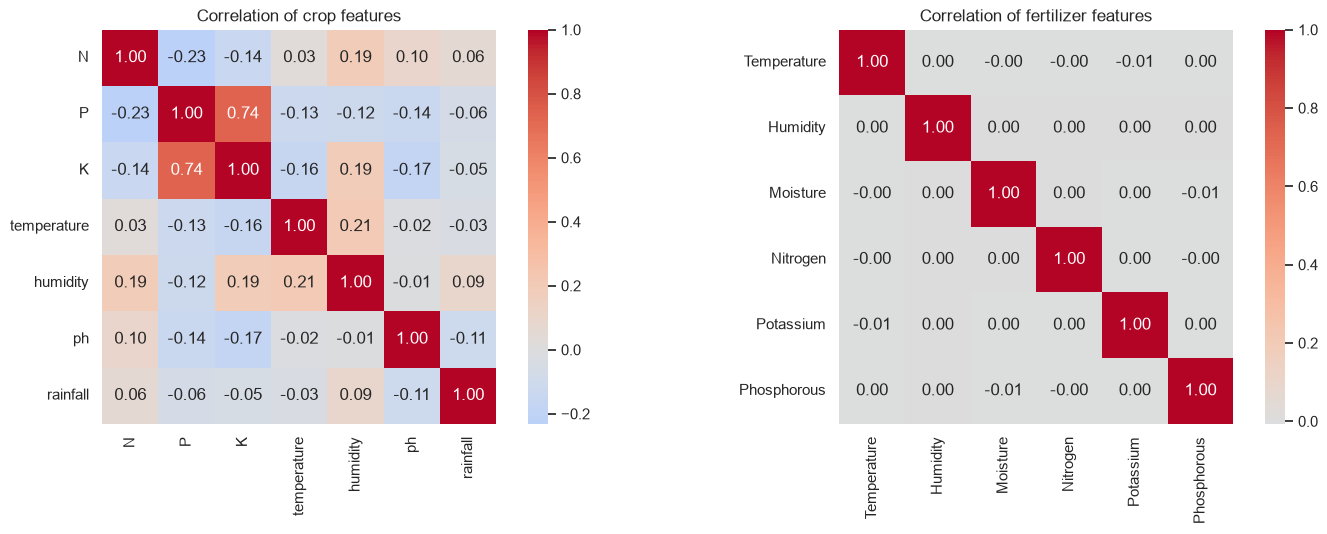

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(crop.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=axes[0])
axes[0].set_title("Correlation of crop features")
sns.heatmap(fert.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=axes[1])
axes[1].set_title("Correlation of fertilizer features")
plt.tight_layout()
plt.show()

## 5. Boxplots: crop features by crop, fertilizer nutrients by fertilizer

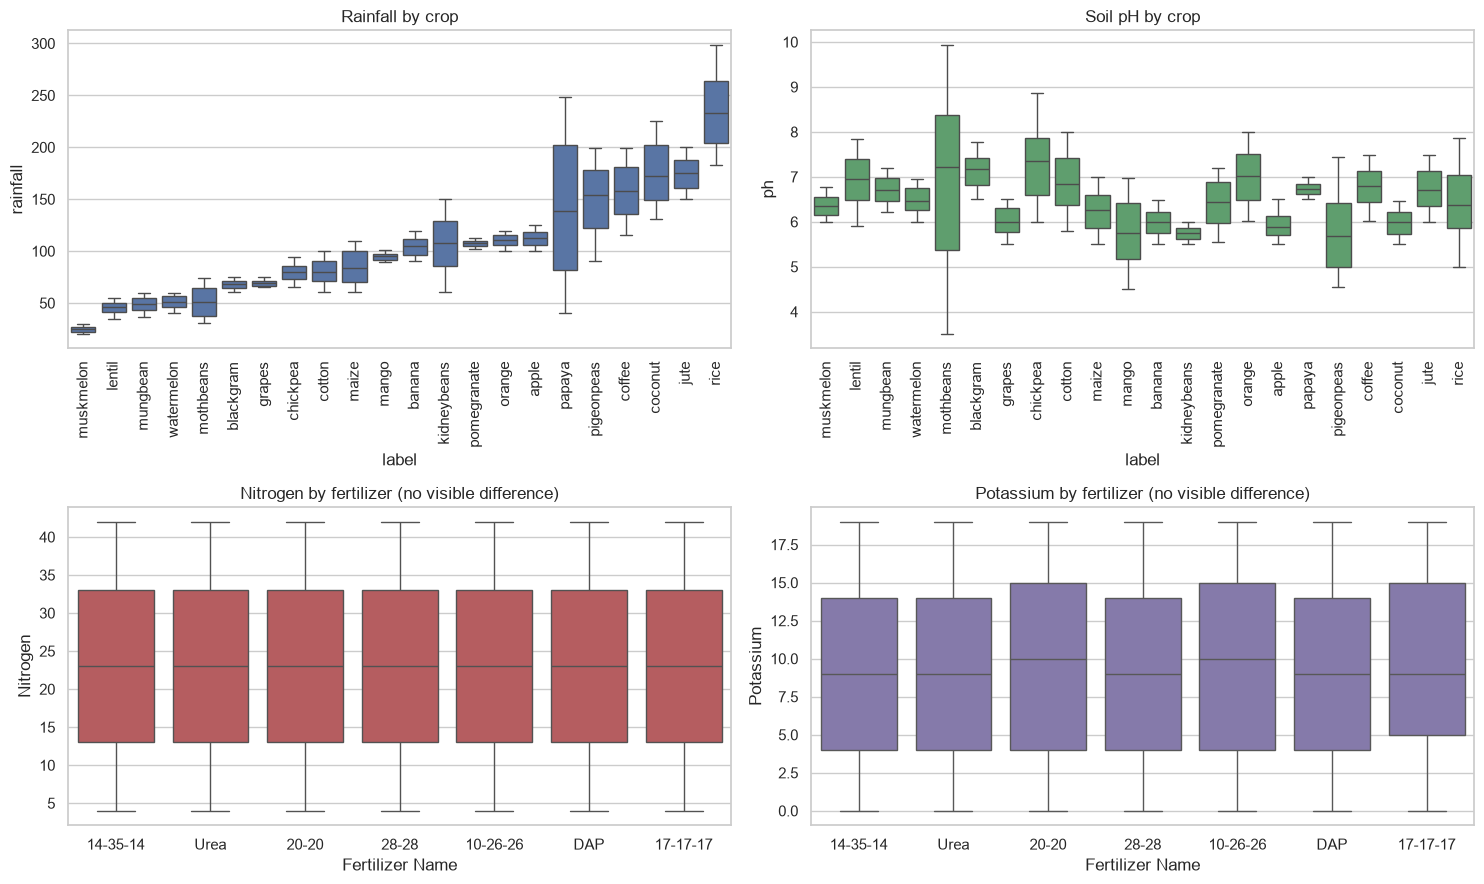

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
order = crop.groupby(CROP_TARGET)["rainfall"].median().sort_values().index
sns.boxplot(data=crop, x=CROP_TARGET, y="rainfall", order=order, ax=axes[0, 0], color="#4c72b0")
axes[0, 0].set_title("Rainfall by crop"); axes[0, 0].tick_params(axis="x", rotation=90)
sns.boxplot(data=crop, x=CROP_TARGET, y="ph", order=order, ax=axes[0, 1], color="#55a868")
axes[0, 1].set_title("Soil pH by crop"); axes[0, 1].tick_params(axis="x", rotation=90)
sns.boxplot(data=fert, x=FERT_TARGET, y="Nitrogen", ax=axes[1, 0], color="#c44e52")
axes[1, 0].set_title("Nitrogen by fertilizer (no visible difference)")
sns.boxplot(data=fert, x=FERT_TARGET, y="Potassium", ax=axes[1, 1], color="#8172b2")
axes[1, 1].set_title("Potassium by fertilizer (no visible difference)")
plt.tight_layout()
plt.show()

## 6. Scatter plots

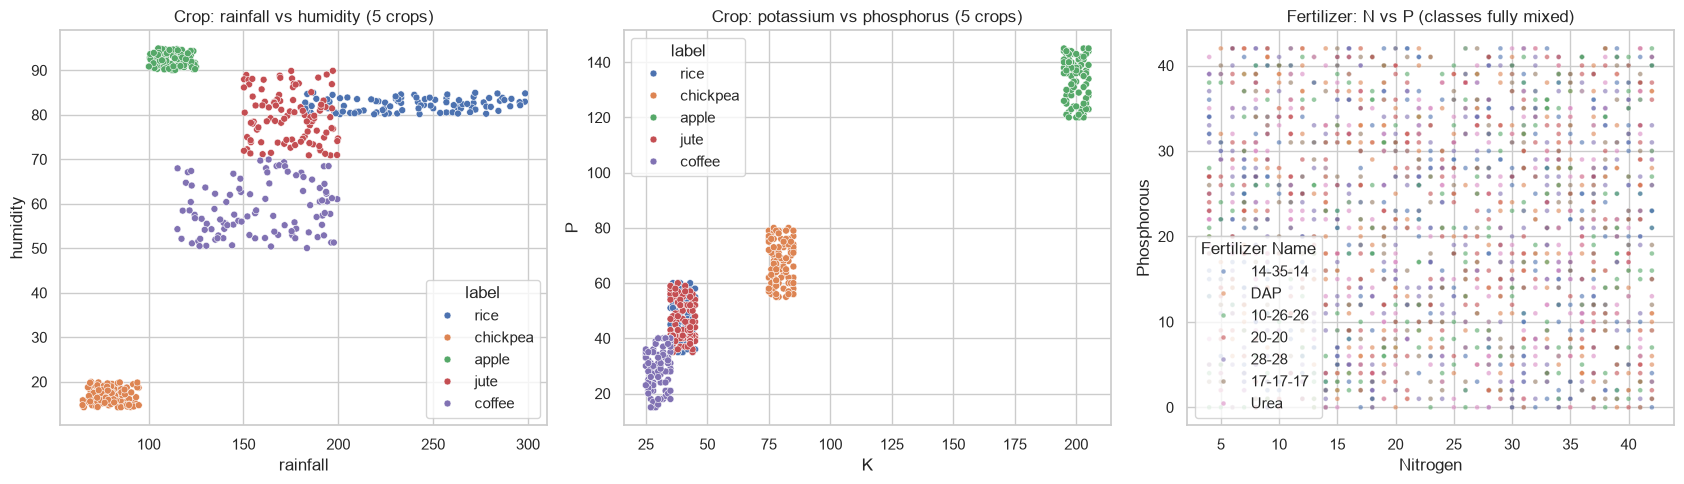

In [9]:
top = ["rice", "jute", "chickpea", "apple", "coffee"]
sub = crop[crop[CROP_TARGET].isin(top)]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=sub, x="rainfall", y="humidity", hue=CROP_TARGET, ax=axes[0], s=25)
axes[0].set_title("Crop: rainfall vs humidity (5 crops)")
sns.scatterplot(data=sub, x="K", y="P", hue=CROP_TARGET, ax=axes[1], s=25)
axes[1].set_title("Crop: potassium vs phosphorus (5 crops)")
samp = fert.sample(2000, random_state=42)
sns.scatterplot(data=samp, x="Nitrogen", y="Phosphorous", hue=FERT_TARGET, ax=axes[2], s=12, alpha=0.6)
axes[2].set_title("Fertilizer: N vs P (classes fully mixed)")
plt.tight_layout()
plt.show()

## 7. Feature importance (Random Forest)

Crop - Random Forest hold-out accuracy: 99.55%


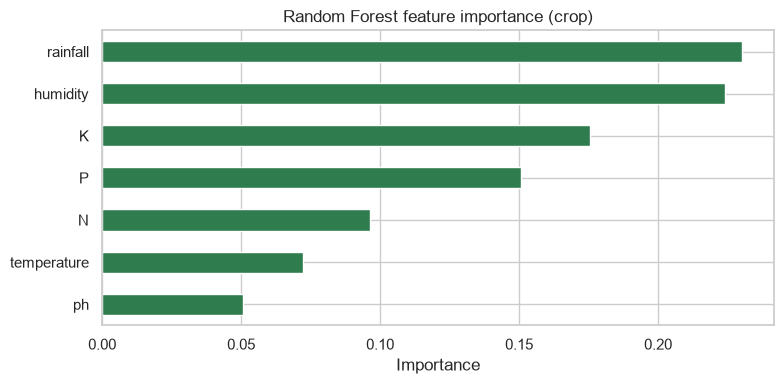

rainfall       0.2302
humidity       0.2242
K              0.1754
P              0.1508
N              0.0964
temperature    0.0724
ph             0.0506
dtype: float64

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

Xc, yc = crop.drop(columns=CROP_TARGET), crop[CROP_TARGET]
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xtr, ytr)
print("Crop - Random Forest hold-out accuracy: %.2f%%" % (100 * rf.score(Xte, yte)))

imp = pd.Series(rf.feature_importances_, index=Xc.columns).sort_values()
imp.plot(kind="barh", color="#2f7d4f", figsize=(8, 4))
plt.title("Random Forest feature importance (crop)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(4)

## 8. Model comparison and the fertilizer data audit

               Crop CV accuracy (%)  Fertilizer CV accuracy (%)
Model                                                          
Random Forest                 99.50                       13.95
Decision Tree                 98.68                       14.18
KNN (k=5)                     97.14                       14.17


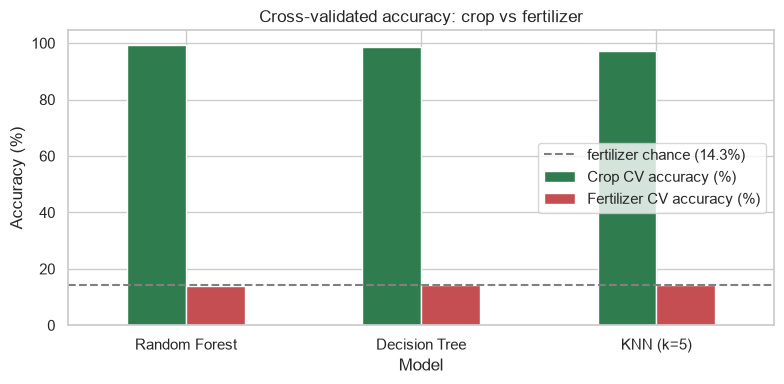


One-way ANOVA of each nutrient across the 7 fertilizers (p > 0.05 means no difference):
  Temperature  p = 0.9474
  Humidity     p = 0.4036
  Moisture     p = 0.4124
  Nitrogen     p = 0.6115
  Phosphorous  p = 0.3720
  Potassium    p = 0.2781


In [11]:
from scipy import stats
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

models = {"Random Forest": RandomForestClassifier(100, random_state=42), "Decision Tree": DecisionTreeClassifier(random_state=42),
          "KNN (k=5)": KNeighborsClassifier(5)}
fs = fert.sample(20000, random_state=42)
Xf = pd.get_dummies(fs.drop(columns=FERT_TARGET)).astype(float)
yf = fs[FERT_TARGET]
rows = []
for n, m in models.items():
    c = cross_val_score(make_pipeline(StandardScaler(), m), Xc, yc, cv=5).mean() * 100
    f = cross_val_score(make_pipeline(StandardScaler(), m), Xf, yf, cv=3).mean() * 100
    rows.append((n, round(c, 2), round(f, 2)))
res = pd.DataFrame(rows, columns=["Model", "Crop CV accuracy (%)", "Fertilizer CV accuracy (%)"]).set_index("Model")
print(res)

ax = res.plot(kind="bar", figsize=(8, 4), color=["#2f7d4f", "#c44e52"], rot=0)
ax.axhline(100 / 7, color="gray", ls="--", label="fertilizer chance (14.3%)")
ax.set_ylabel("Accuracy (%)"); ax.set_title("Cross-validated accuracy: crop vs fertilizer"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

print("\nOne-way ANOVA of each nutrient across the 7 fertilizers (p > 0.05 means no difference):")
for col in ["Temperature", "Humidity", "Moisture", "Nitrogen", "Phosphorous", "Potassium"]:
    p = stats.f_oneway(*[g[col].values for _, g in fert.groupby(FERT_TARGET)]).pvalue
    print(f"  {col:12s} p = {p:.4f}")

**Finding.** The crop data is clean and separable (about 99% accuracy). On the fertilizer data every model scores at chance (about 14%) and no feature differs between fertilizers, so the labels carry no learnable signal. The web application reports this with a reliability warning.

## 9. Application demo (screenshots of the running web application)

**Crop Predictor**

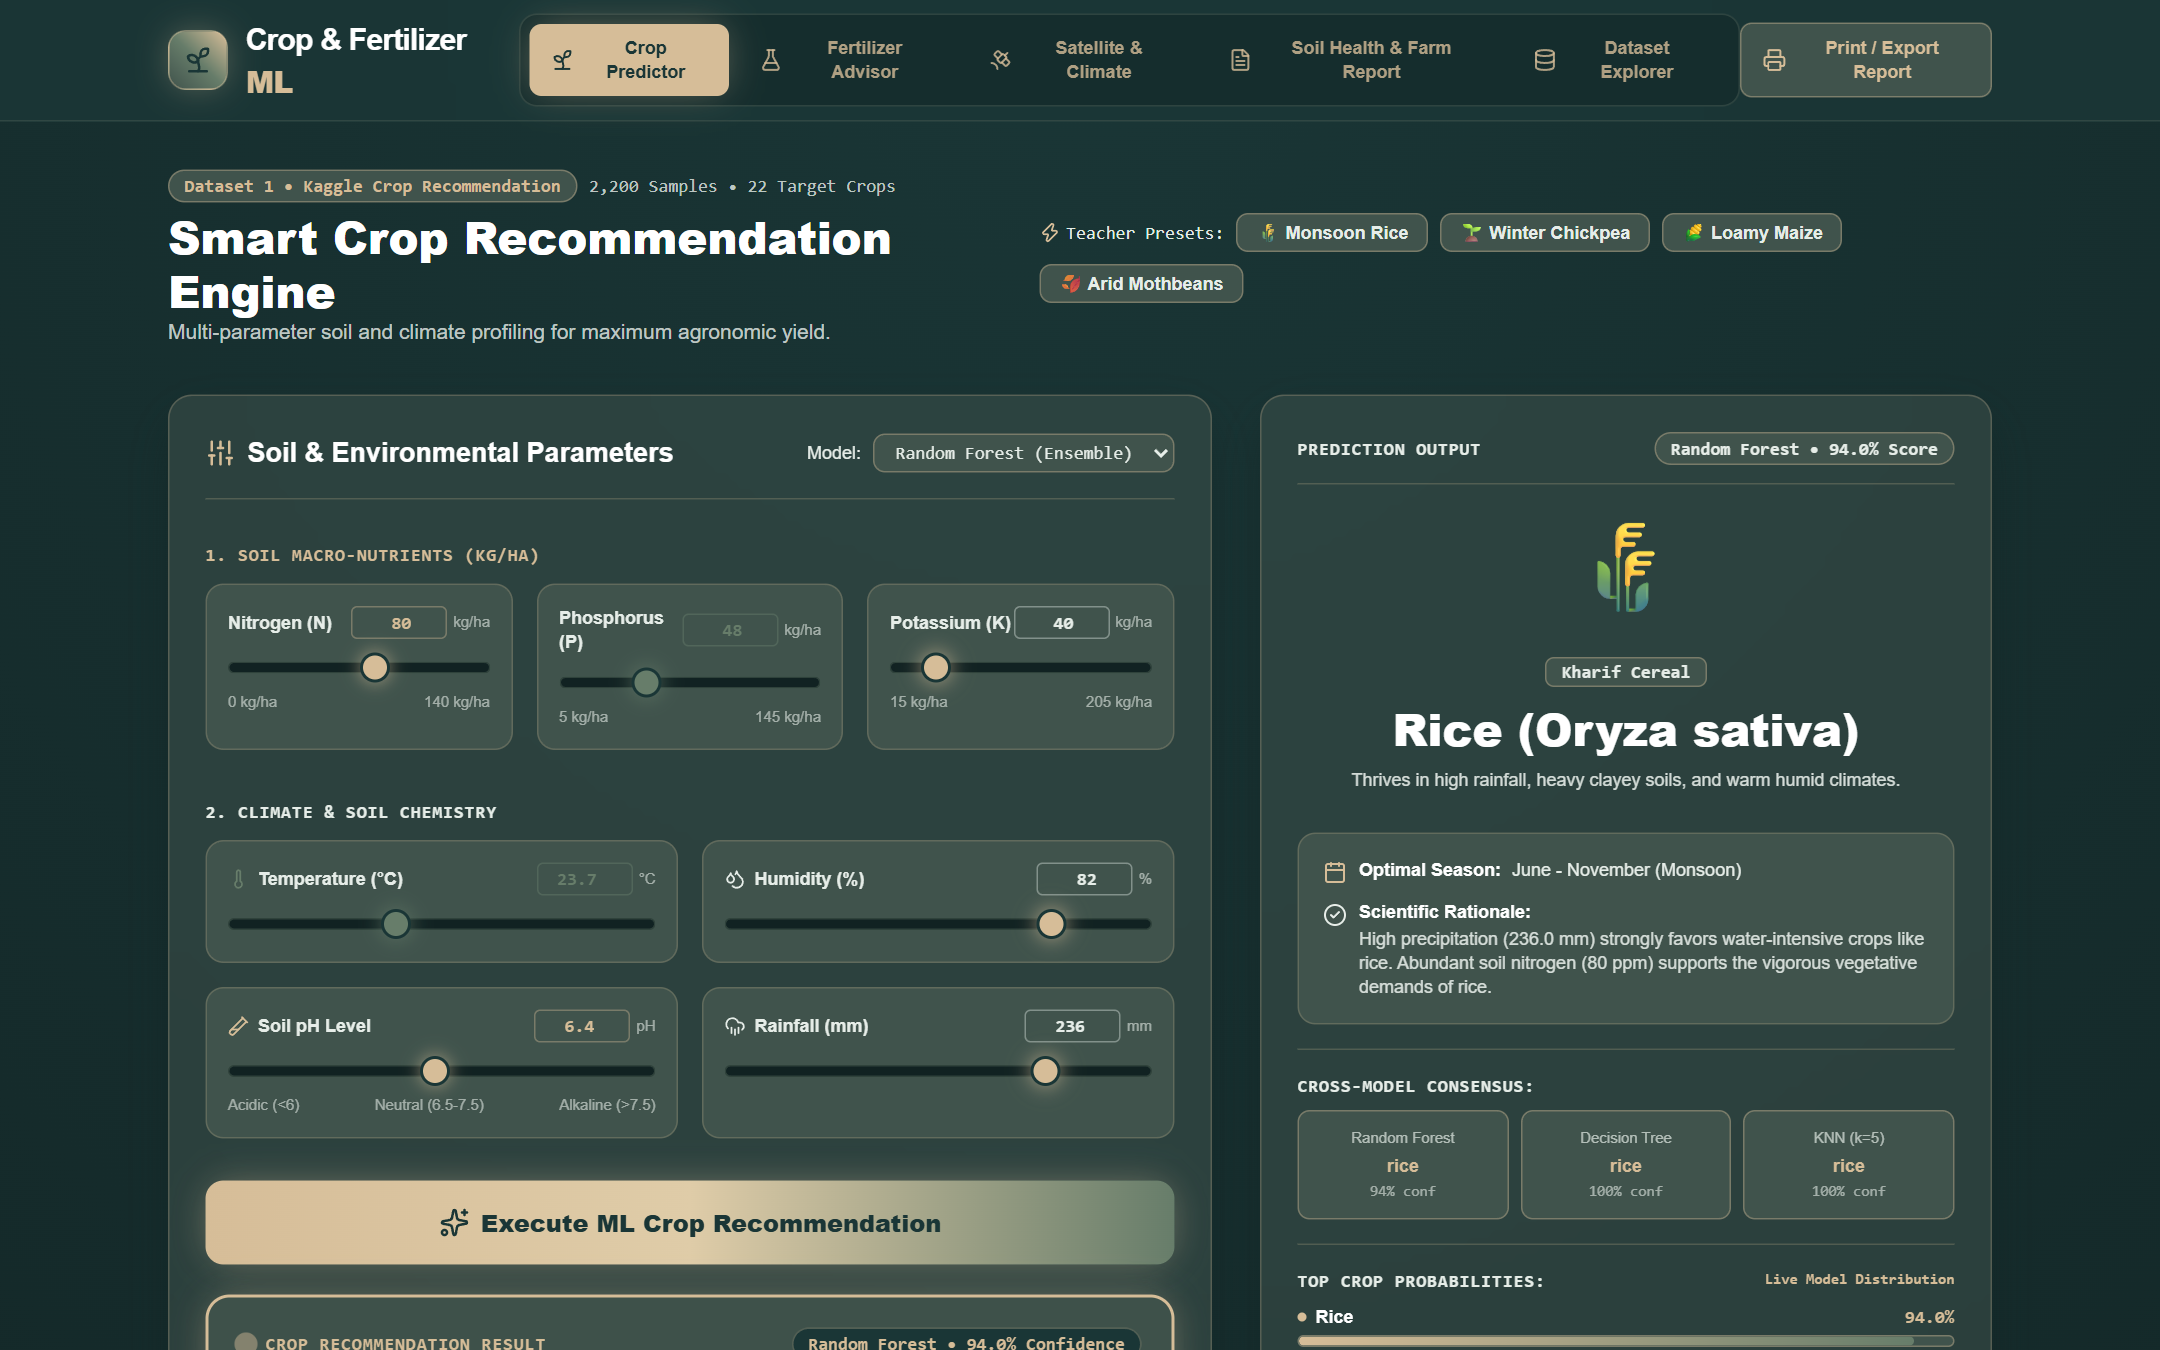

In [12]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "report" / "figures" / "ui_crop.png"), width=900))

**Fertilizer Advisor (with reliability warning)**

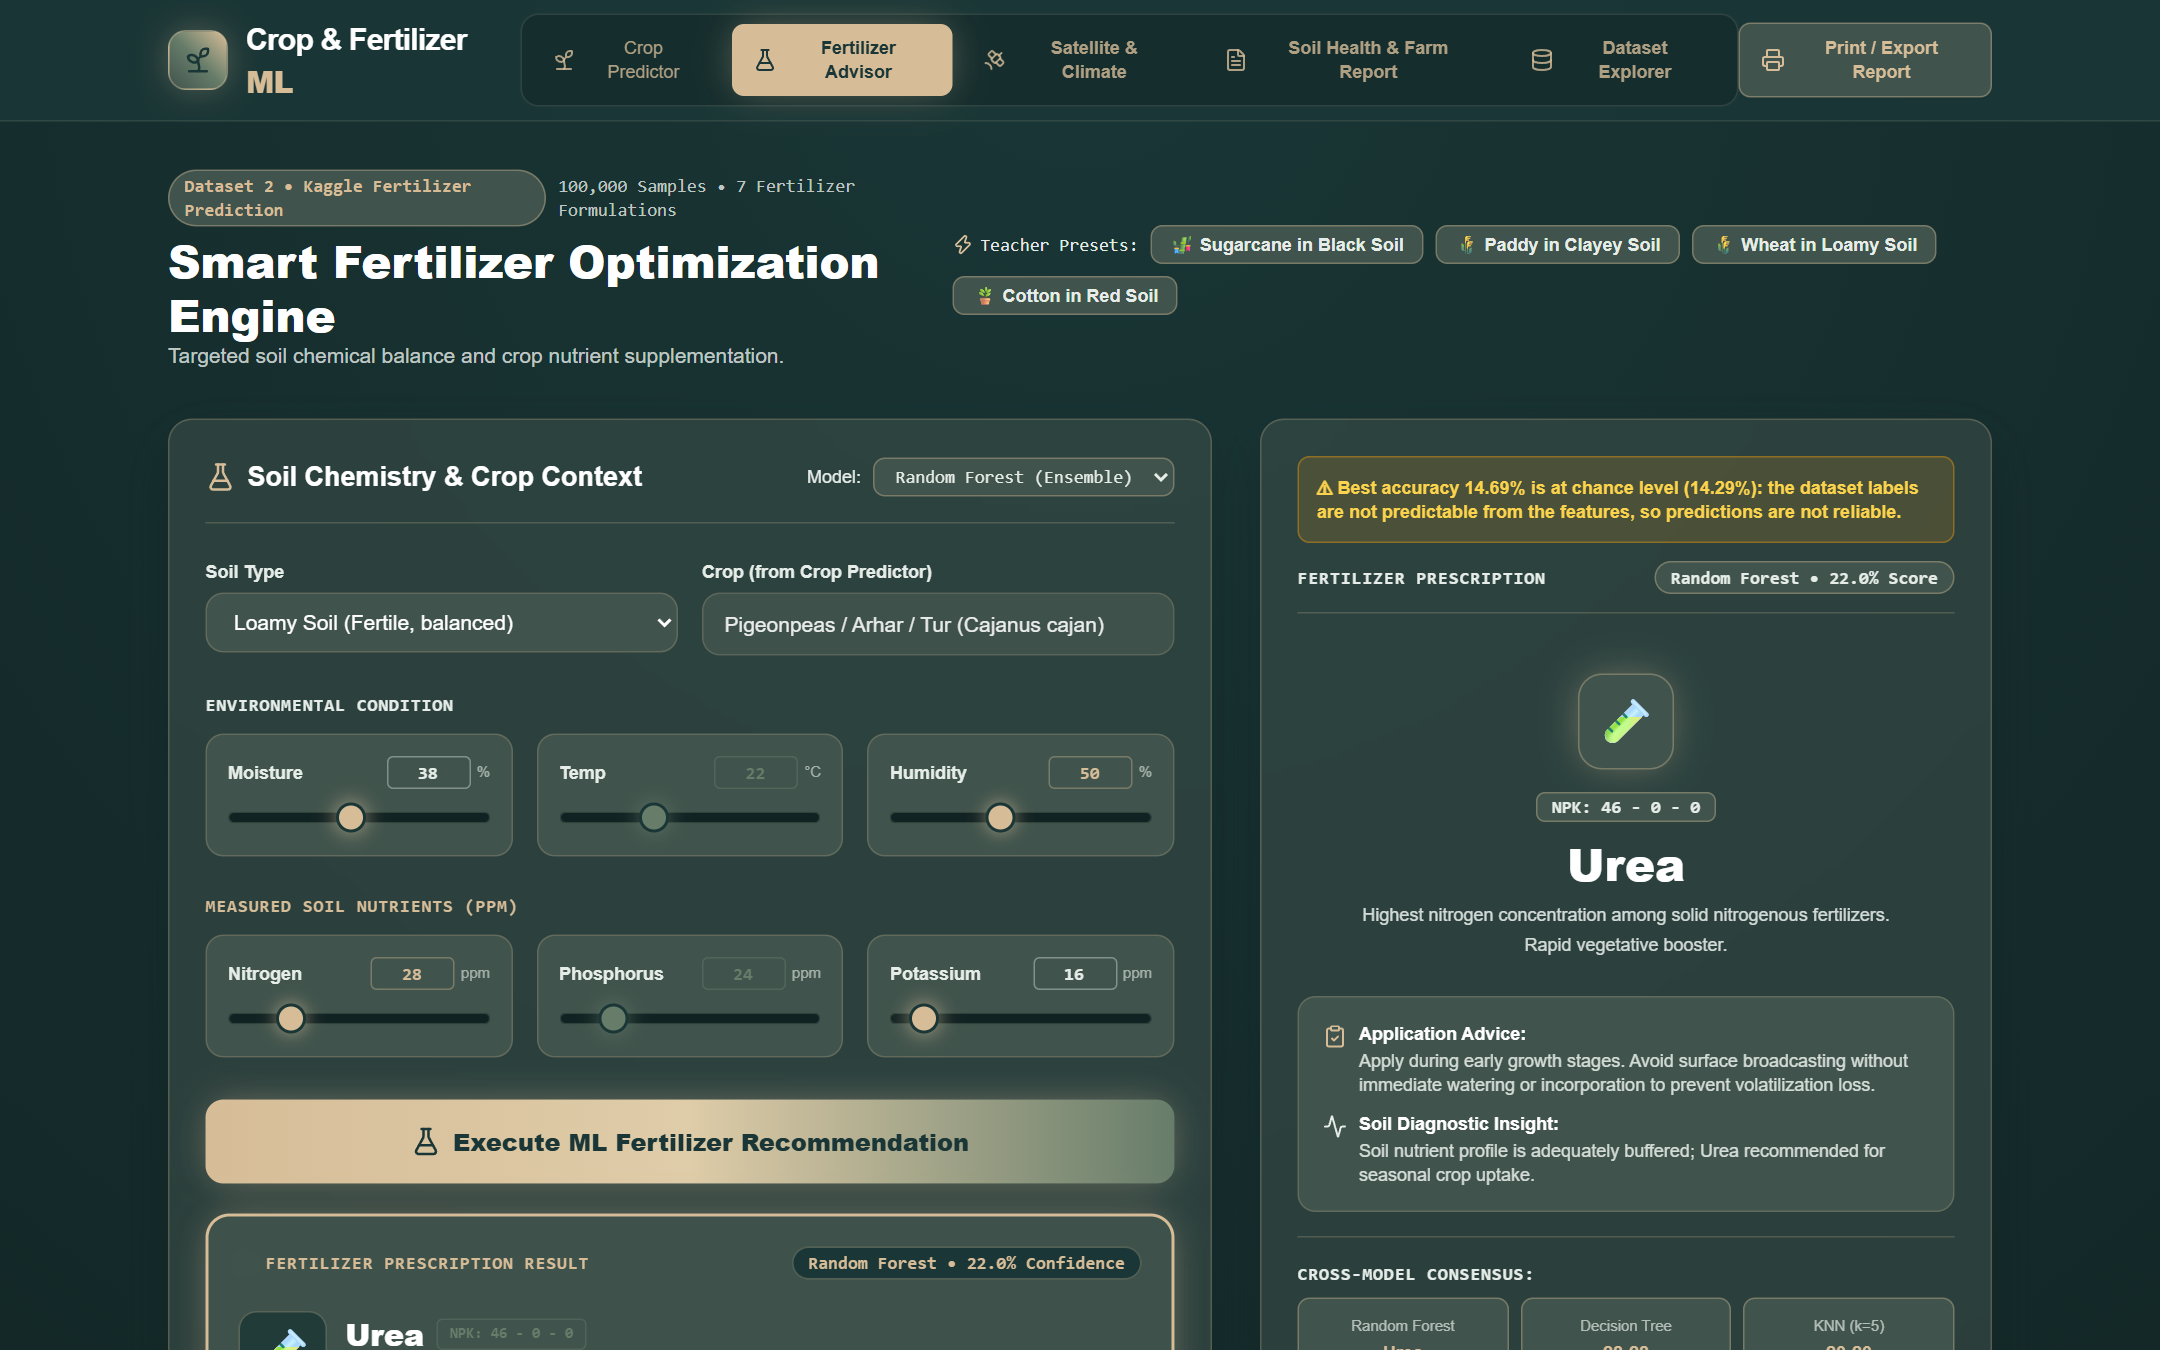

In [13]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "report" / "figures" / "ui_fertilizer.png"), width=900))

**Satellite and Climate**

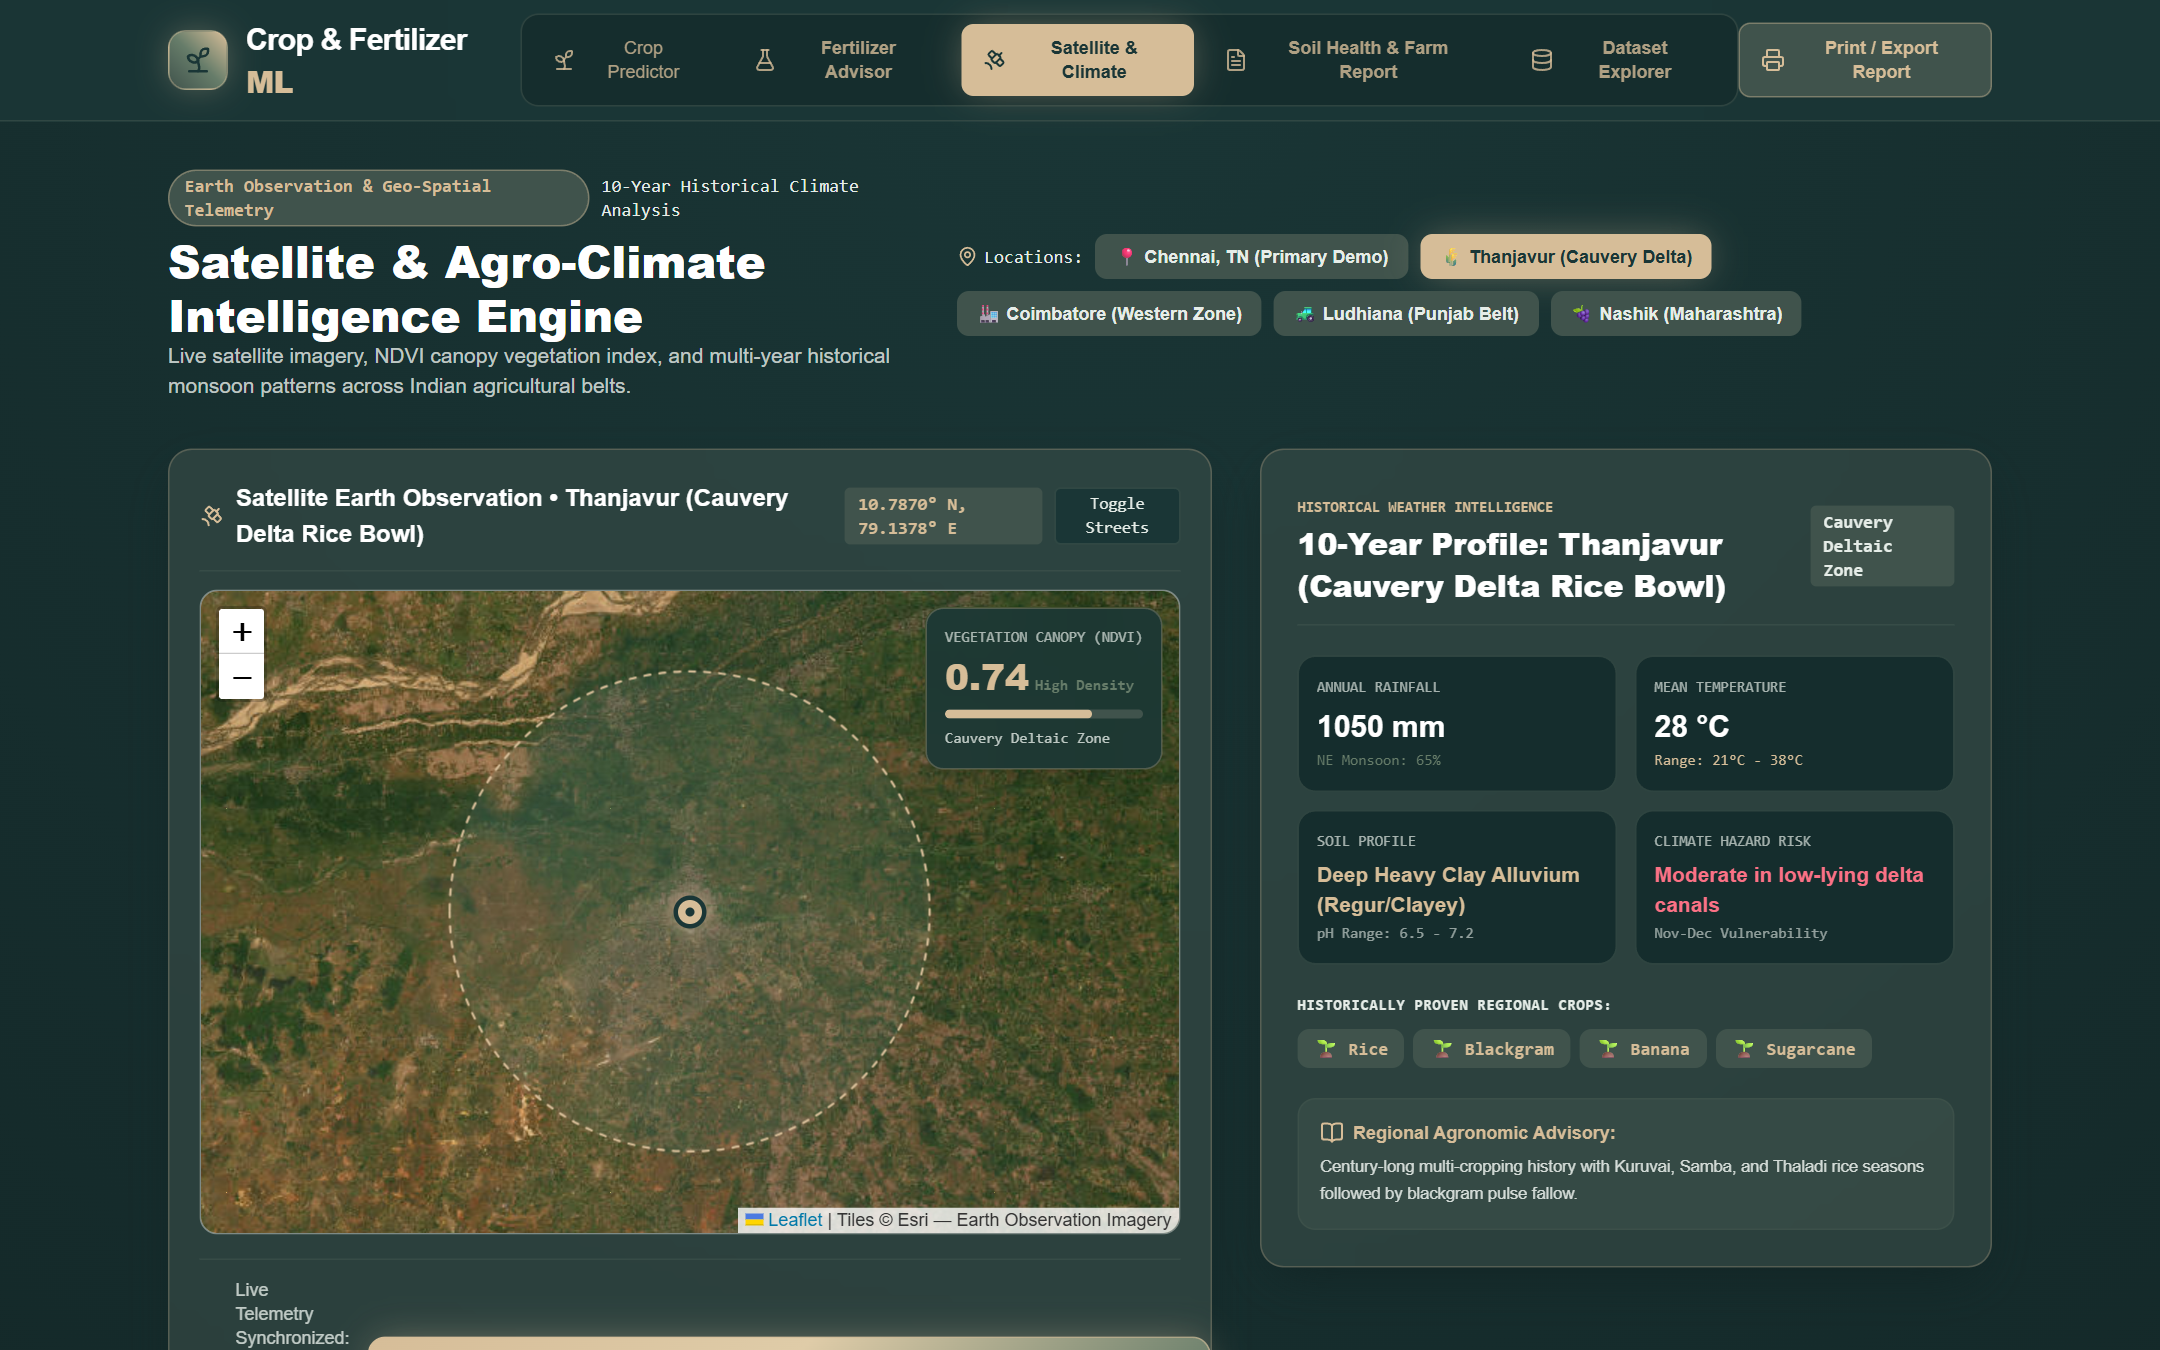

In [14]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "report" / "figures" / "ui_satellite.png"), width=900))

**Soil Health and Farm Advisory Report**

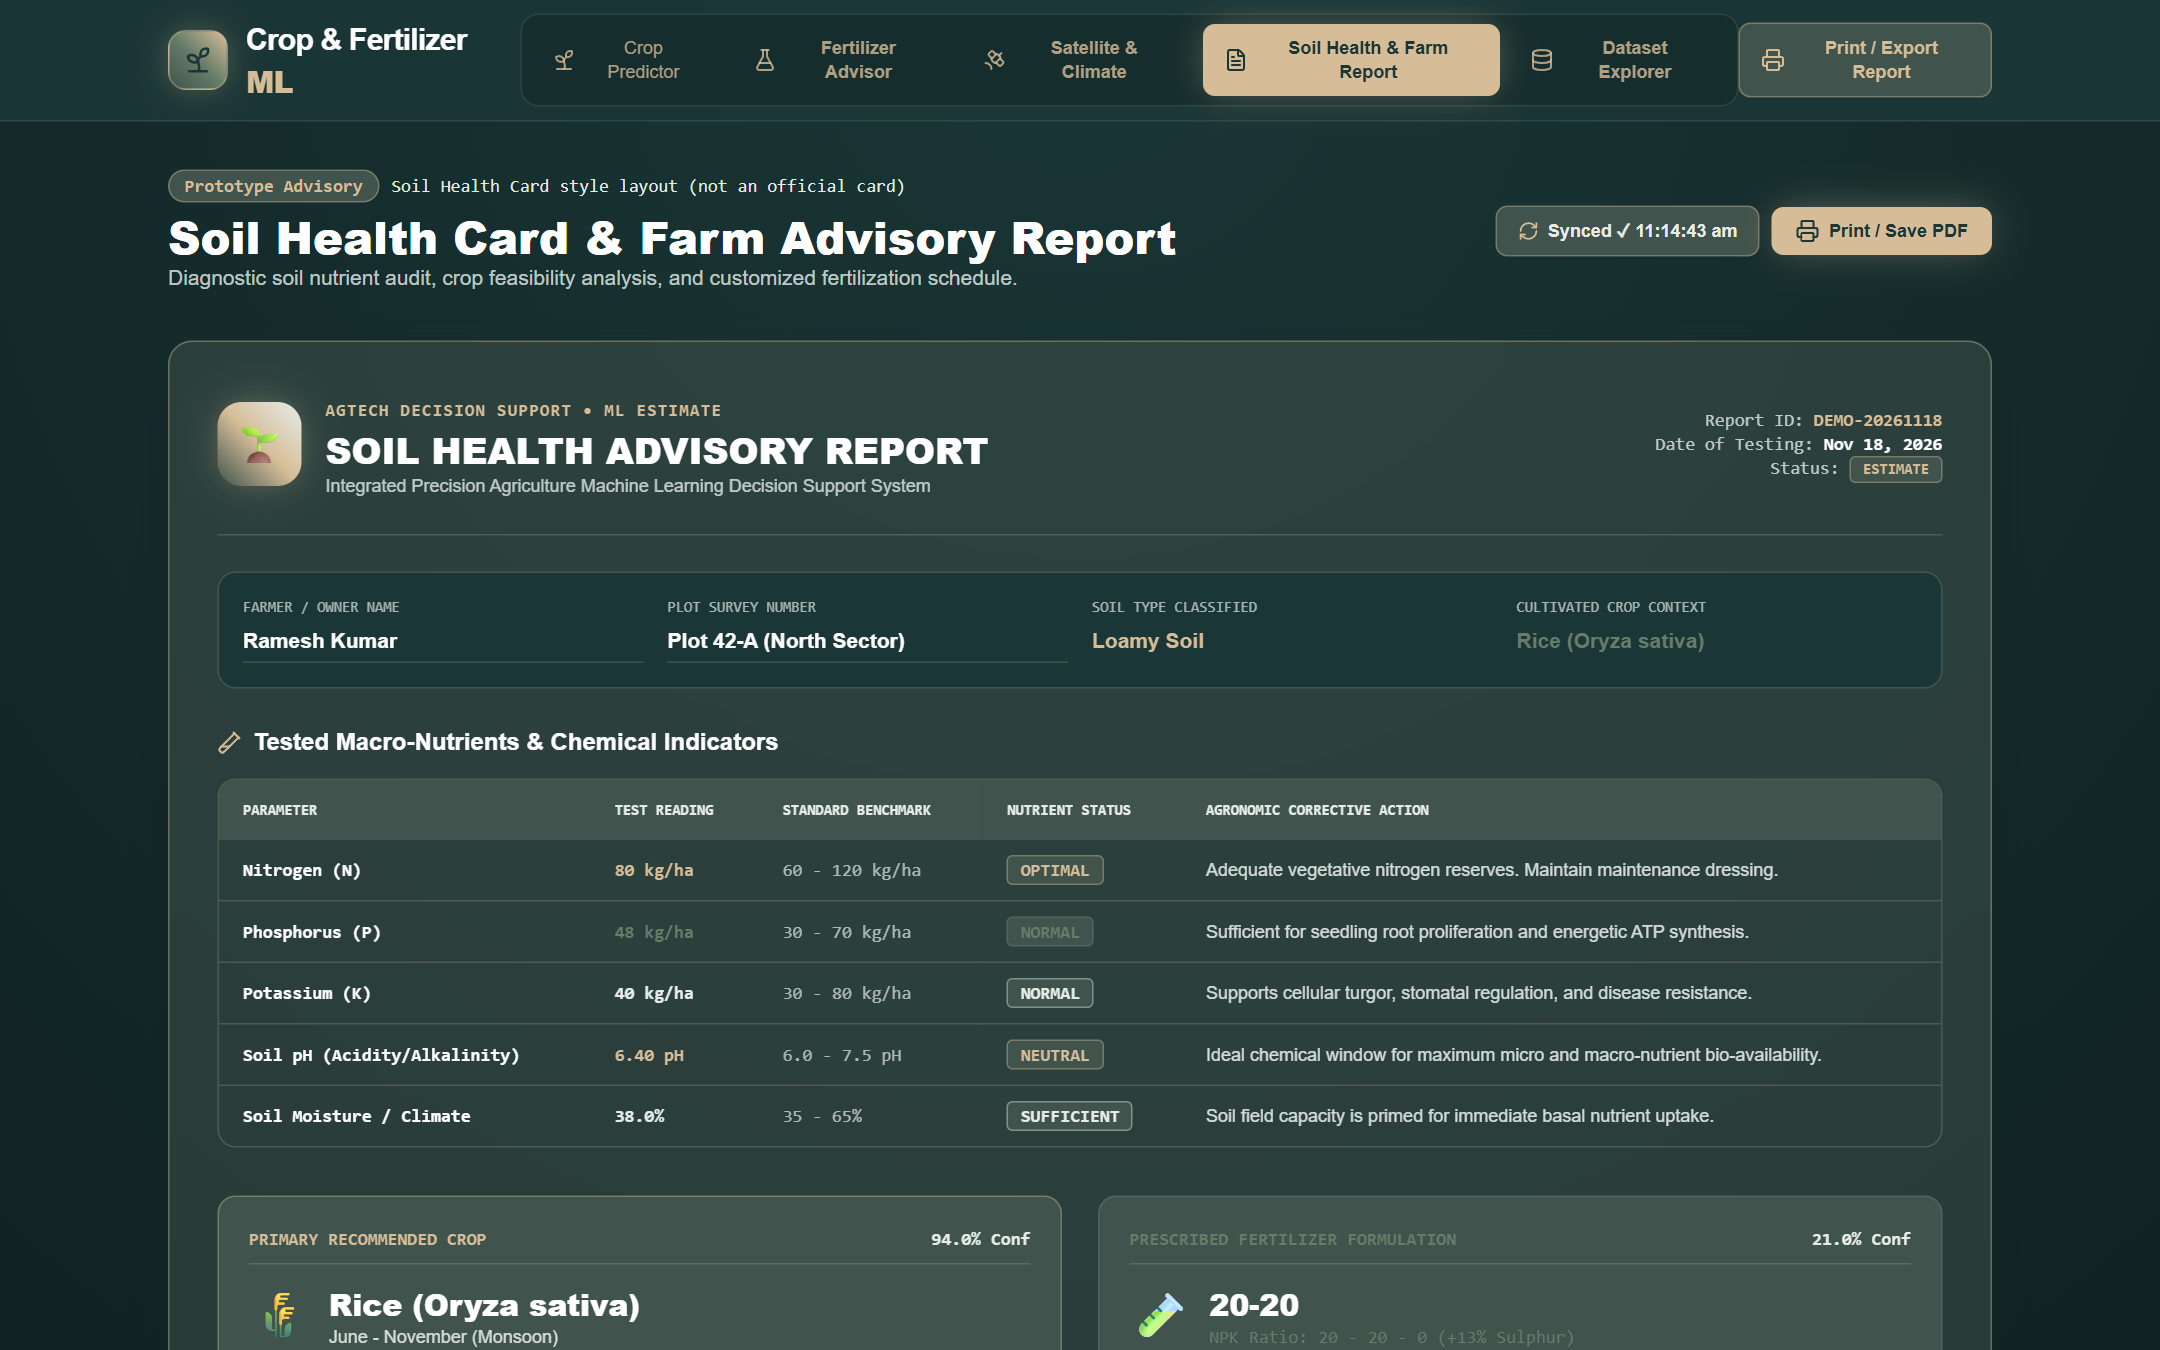

In [15]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "report" / "figures" / "ui_report.png"), width=900))

**Dataset Explorer**

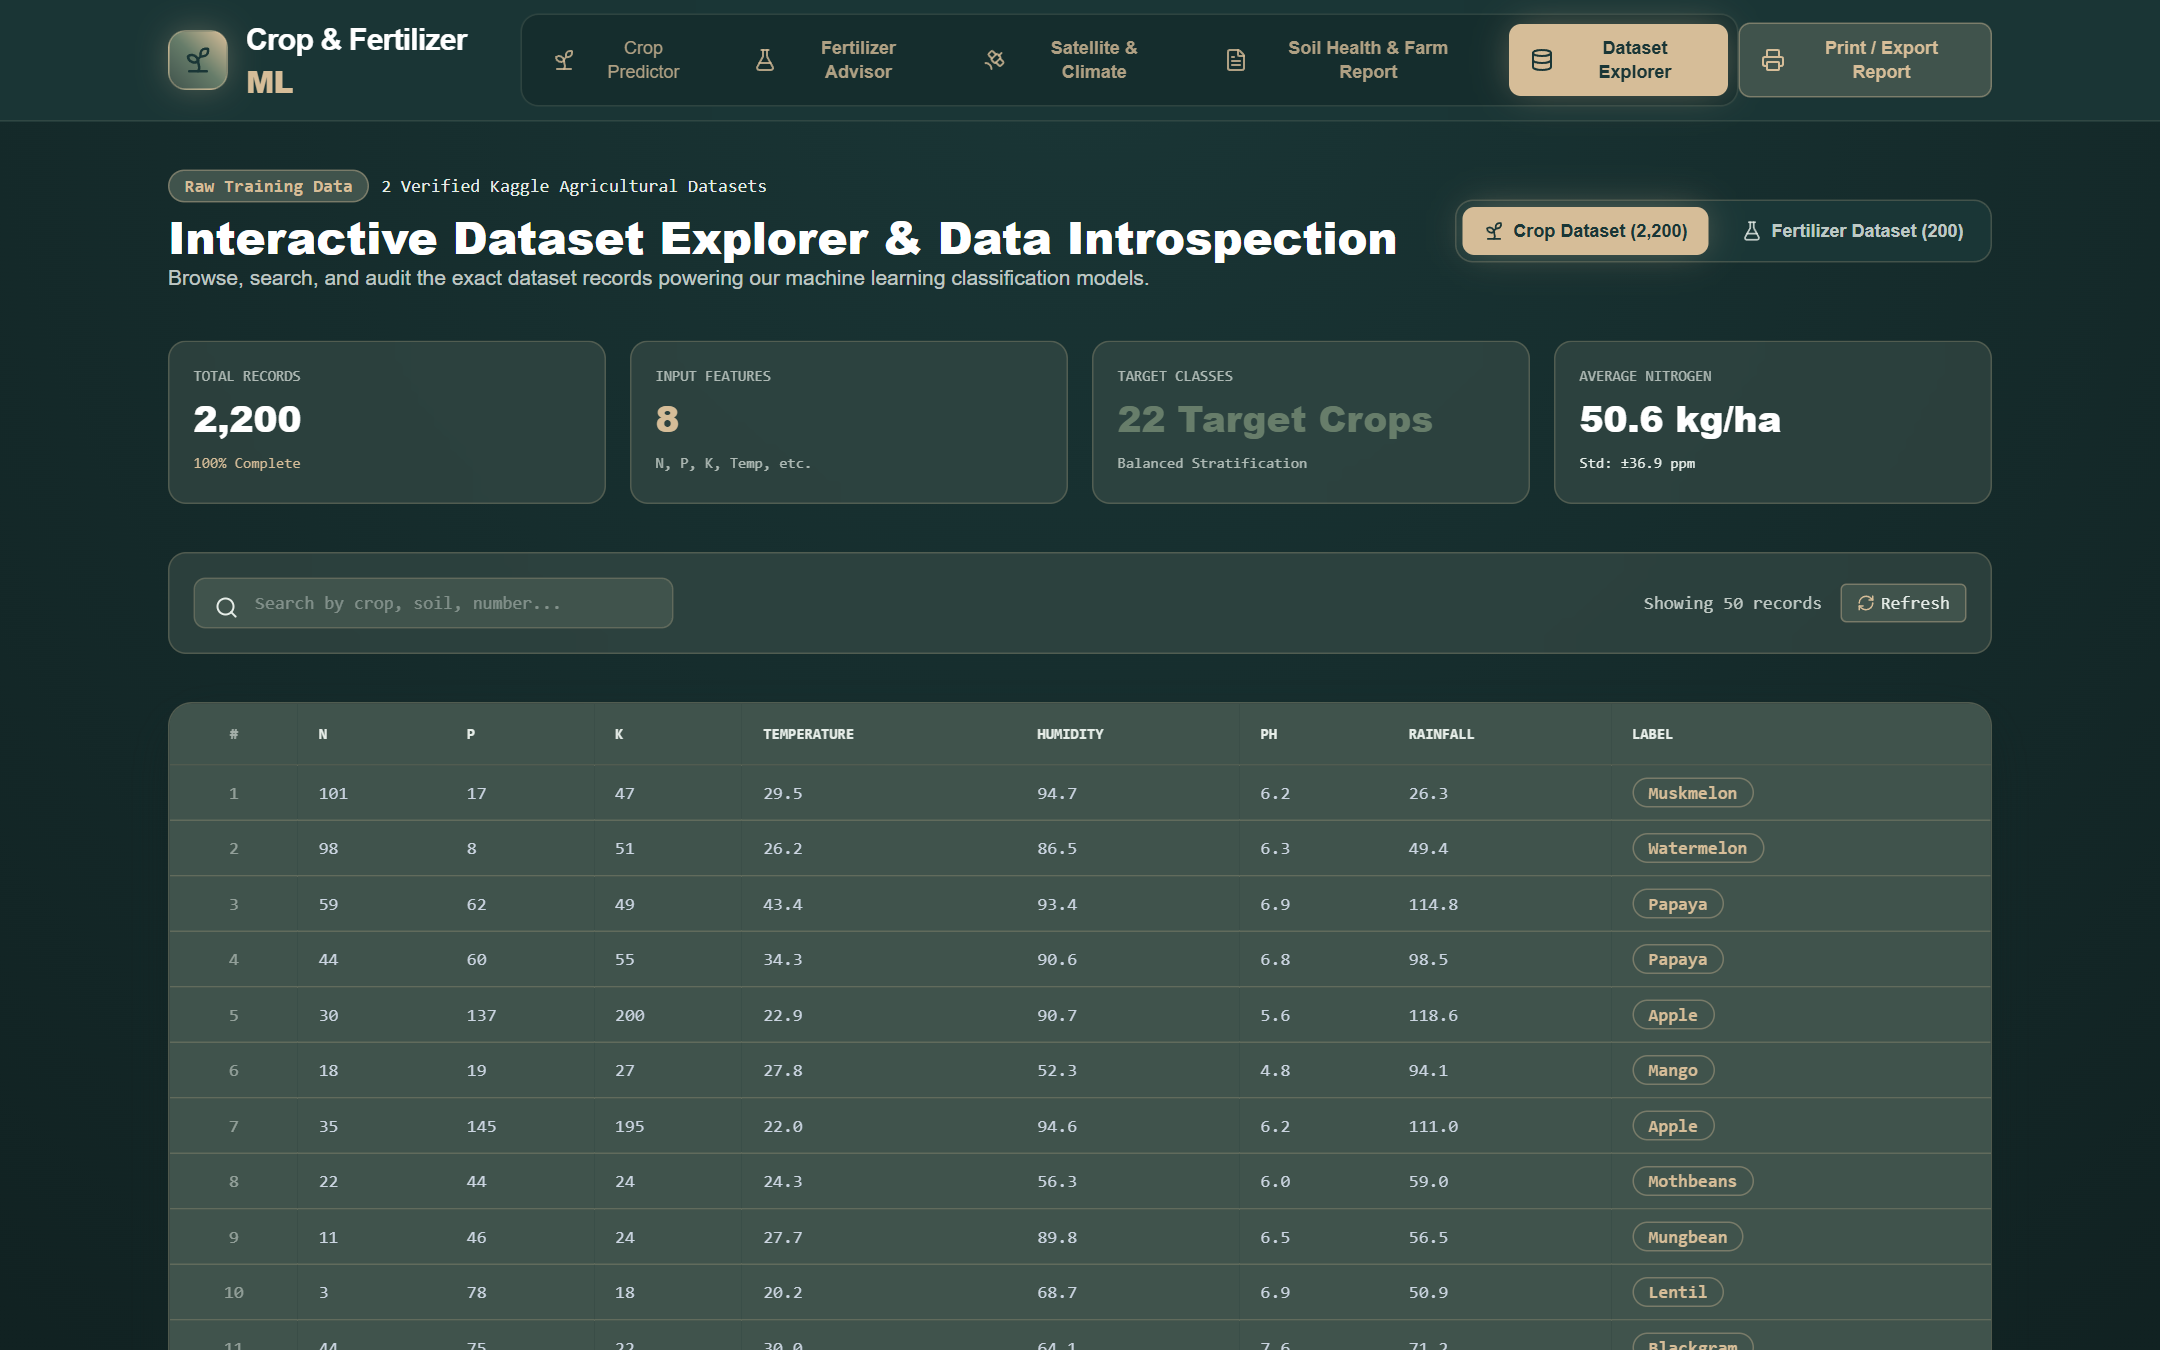

In [16]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "report" / "figures" / "ui_dataset.png"), width=900))